## Adição de ruído sobre o sinal
Este caderno descreve como é feita a adição de ruído sobre o sinal GRE simulado. 

#### O ruído riciano tem a seguinte característica:

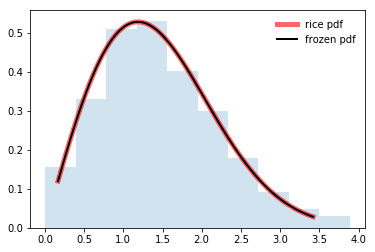

In [1]:
#bibliotecas para incializar
# -*- coding: utf-8 -*-
from scipy.stats import rice
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 1)

#Calculate a few first moments:
b = 0.8
mean, var, skew, kurt = rice.stats(b, moments='mvsk')

#Display the probability density function (pdf):
x = np.linspace(rice.ppf(0.01, b),
rice.ppf(0.99, b), 100)
ax.plot(x, rice.pdf(x, b),'r-', lw=5, alpha=0.6, label='rice pdf')

#Alternatively, freeze the distribution and display the frozen pdf:
rv = rice(b)
ax.plot(x, rv.pdf(x), 'k-', lw=2, label='frozen pdf')

#Check accuracy of cdf and ppf:
vals = rice.ppf([0.001, 0.5, 0.999], b)
np.allclose([0.001, 0.5, 0.999], rice.cdf(vals, b))
True

#Generate random numbers:
r = rice.rvs(b, size=1000)

#And compare the histogram:
ax.hist(r, normed=True, histtype='stepfilled', alpha=0.2)
ax.legend(loc='best', frameon=False)
plt.show()


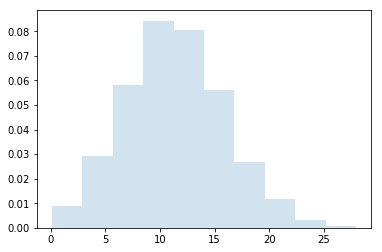

In [2]:
#bibliotecas para incializar
# -*- coding: utf-8 -*-
from scipy.stats import rice
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 1)

b = 20

#Generate random numbers:
r = rice.rvs(2, 0, 5, size=8000)

#And compare the histogram:
ax.hist(r, normed=True, histtype='stepfilled', alpha=0.2)
plt.show()




O ruido riciano é descrito como vindo da interação entre dois um emissor e um receptor sujeitos a ruído gaussiano independente, e depois aplicado módulo sobre o sinal. É o que acontece no sinal gradiente de módulo adquirido em quadratura:
* Imaginemos uma região uniforme do fígado, onde cada pixel tem um valor médio *mu* homogêneo;
* Esse valor foi obtido a partir do módulo sqrt(R²+IM²) dos sinais de cada bobina em quadratura;
* Mas cada bobina também contribui com ruído aleatório r+im com distribuição gaussiana, com média zero e desvio padrão *sigma*, portanto, o valor de cada pixel tem um incremento aleatório dado pelas parcelas de cada bobina sqrt((R+r)²+(IM+im)²);
* Após a operação de módulo, essa distribuição gaussiana é alterada e passa a ser chamada riciana. Se olharmos para uma região sem sinal ou próximo de zero (*mu ~ 0*), a forma fica visivelmente diferente. No caso sem sinal, a distribuição é chamada de Rayleigh.
* No entanto, onde há bastante sinal (*mu >> 0*, ou *mu/sigma*>2), a distribuição volta a se parecer Gaussiana com média maior que zero.
* Para gerar o ruído então, parece mais adequado gerar duas distribuições gaussianas independentes com média zero e mesmo desvio padrão, obter o módulo de suas parcelas e adicionar este valor na equação do sinal simulado dependente de TE, (**antes de tirar o módulo?**).
    * Mas ao colocar a interferencia de duas gaussianas com media zero, não estaremos adicionando uma distribuição de Rayleigh?
    * Se com sinal a distribuição parece gaussiana, isso significa que o ruido passa a ser tanto aditivo quanto subtrativo em relação à média? Como aparece o subtrativo? Ou é apenas o left tail que aumenta?

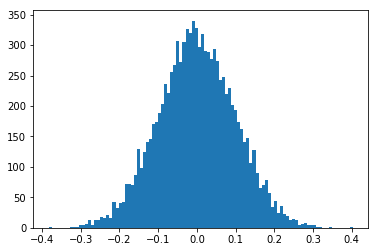

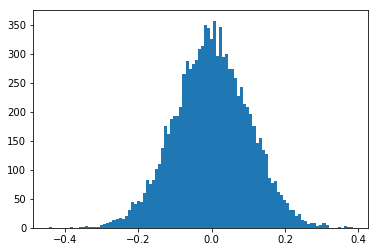

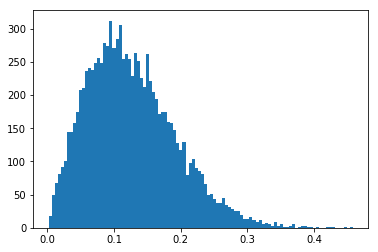

In [36]:
mu, sigma = 0, 0.1 # mean and standard deviation

g1 = np.random.normal(mu, sigma, 10000)
g2 = np.random.normal(mu, sigma, 10000)
g3 = np.sqrt(g1**2+g2**2)

plt.hist(g1, bins=100)
plt.show()

plt.hist(g2, bins=100)
plt.show()

plt.hist(g3, bins=100)
plt.show()


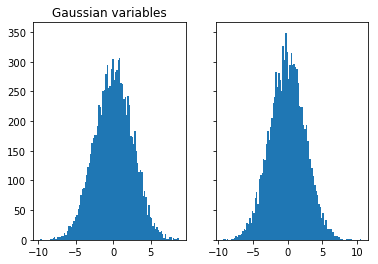

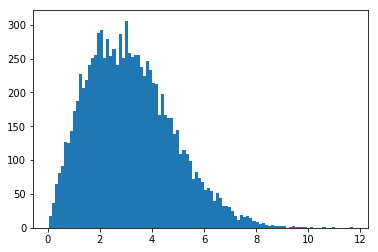

In [81]:
from IPython.html.widgets import *

def g(mu, sigma):
#mu, sigma = 0, 0.1 # mean and standard deviation
    g1 = np.random.normal(mu, sigma, 10000)
    g2 = np.random.normal(mu, sigma, 10000)
    g3 = np.sqrt(g1**2+g2**2)

    f, (ax1, ax2) = plt.subplots(1, 2, sharey=True)
    ax1.hist(g1, bins = 100)
    ax1.set_title('Gaussian variables')
    ax2.hist(g2, bins = 100)
    plt.show()

    plt.hist(g3, bins=100)
    plt.show()

interact (g, mu=(0, 50, 1), sigma=(0.1, 5, 0.1))


* Para gerar o ruído então, parece mais adequado gerar duas distribuições gaussianas independentes com média zero e mesmo desvio padrão, obter o módulo de suas parcelas e adicionar este valor na equação do sinal simulado dependente de TE, (**antes de tirar o módulo?**).
    * Mas ao colocar a interferencia de duas gaussianas com media zero, não estaremos adicionando uma distribuição de Rayleigh?
    * Se com sinal a distribuição parece gaussiana, isso significa que o ruido passa a ser tanto aditivo quanto subtrativo em relação à média? Como aparece o subtrativo? Ou é apenas o left tail que aumenta?
* Para verficar, vamos adicionar o ruido à uma linha reta (y) dentro e fora do modulo (ou seja, com abs(y+rx+ry) e com y+abs(rx+ry) e ver como ele se diferencia.

curva original: imagine uma região de sinal uniforme = 100


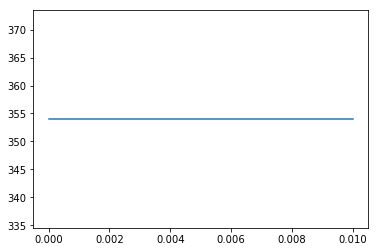

curva com ruído abs(Sinal+rx+ry), observe que o ruído se expande para os dois lados


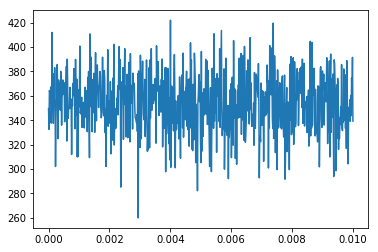

curva com ruído abs(Sinal)+abs(rx+ry), observe a limitação inferior do sinal em 100


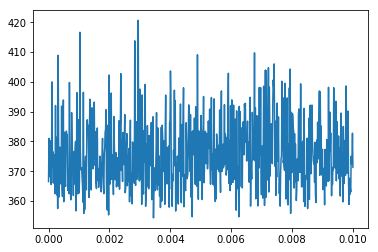

histograma curva com ruído abs(Sinal+rx+ry), formato similar a gaussiano com média não-zero, ou riciano com SNR alto.
a média é zero, como esperado


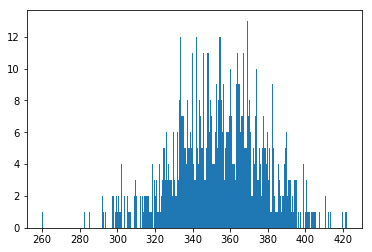

histograma curva com ruído abs(Sinal)+abs(rx+ry), formato similar a Rayleigh, ou riciano com sinal zero
A curva começa em 100, como esperado.


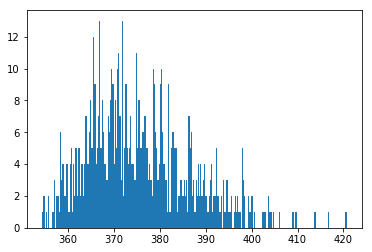

In [86]:
TE = np.linspace(0,0.010,700)
magField = 3.0 #tesla
hydroGyro = 42.57e6 #Hz/T

mu = 0
sigma = 17

g1 = np.random.normal(mu, sigma, 700)
g2 = np.random.normal(mu, sigma, 700)
g3 = np.sqrt(g1**2+g2**2)

'''
y = 90*np.array(np.absolute(1*np.exp(-TE/0.013)*np.exp(2.0*np.pi*1j*1.3*magField*hydroGyro/1e6*TE)+
                 1*np.exp(-TE/0.013)*np.exp(2.0*np.pi*1j*4.7*magField*hydroGyro/1e6*TE)+
                1*np.exp(-TE/0.013)*np.exp(2.0*np.pi*1j*0.9*magField*hydroGyro/1e6*TE)))

y2 = np.array(np.absolute(90*np.exp(-TE/0.013)*np.exp(2.0*np.pi*1j*1.3*magField*hydroGyro/1e6*TE)+
                 90*np.exp(-TE/0.013)*np.exp(2.0*np.pi*1j*4.7*magField*hydroGyro/1e6*TE)+
                90*np.exp(-TE/0.013)*np.exp(2.0*np.pi*1j*0.9*magField*hydroGyro/1e6*TE)+
                           g1+g2))
'''
y = np.linspace(354,354,700)
y2 = abs(y+g1+g2)
#r = rice.rvs(0.5, 0, 1, 10000)

y3 = y+g3
print "curva original: imagine uma região de sinal uniforme = 100"
plt.plot(TE,y)
plt.show()
print "curva com ruído abs(Sinal+rx+ry), observe que o ruído se expande para os dois lados"
plt.plot(TE,y2)
plt.show()
print "curva com ruído abs(Sinal)+abs(rx+ry), observe a limitação inferior do sinal em 100"
plt.plot(TE,y3)
plt.show()

print "histograma curva com ruído abs(Sinal+rx+ry), formato similar a gaussiano com média não-zero, ou riciano com SNR alto."
print "a média é zero, como esperado"
plt.hist(y2, bins=256)
plt.show()
print "histograma curva com ruído abs(Sinal)+abs(rx+ry), formato similar a Rayleigh, ou riciano com sinal zero"
print "A curva começa em 100, como esperado."
plt.hist(y3, bins=256)
plt.show()

curva com ruído abs(Sinal+rx+ry), observe que o ruído se expande para os dois lados


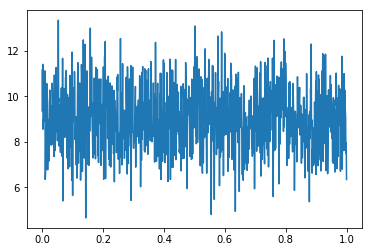

histograma curva com ruído abs(Sinal+rx+ry), formato similar a gaussiano com média não-zero, ou riciano com SNR alto.
a média é zero, como esperado


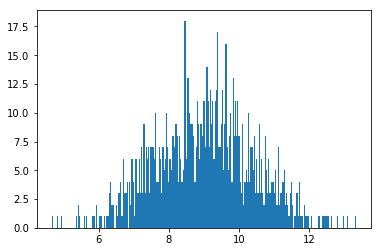

In [98]:
def exp_rice(v):

    TE = np.linspace(0,1,1000)
    mu = 0
    sigma = 1

    g1 = np.random.normal(mu, sigma, 1000)
    g2 = np.random.normal(mu, sigma, 1000)
    g3 = np.sqrt(g1**2+g2**2)

    y = np.linspace(v,v,1000)
    y2 = abs(y+g1+g2)
    #r = rice.rvs(0.5, 0, 1, 10000)

    """print "curva original: imagine uma região de sinal uniforme = 100"
    plt.plot(TE,y)
    plt.show()"""
    print "curva com ruído abs(Sinal+rx+ry), observe que o ruído se expande para os dois lados"
    plt.plot(TE,y2)
    plt.show()
    print "histograma curva com ruído abs(Sinal+rx+ry), formato similar a gaussiano com média não-zero, ou riciano com SNR alto."
    print "a média é zero, como esperado"
    plt.hist(y2, bins=256)
    plt.show()

interact (exp_rice, v=(0, 9, 3))